In [ ]:
# 29-05-2026 - Machine Learning - EDA 

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import warnings

# import the dataset so that we can perform multiple operations 
data = pd.read_csv('insurance.csv')
print(data)

In [ ]:
# Basic operations like to shape, tail, head, value_count, sort_values, 
# to check the size of the dataset 
print(data.shape)

# to count the distinct values in the dataset 
print(data.value_counts())

In [31]:
# head 
data.head()

# tail 
data.tail()

,age,sex,bmi,children,smoker,region,charges
1333,50,male,30.97,3,no,northwest,10600.5483
1334,18,female,31.92,0,no,northeast,2205.9808
1335,18,female,36.85,0,no,southeast,1629.8335
1336,21,female,25.80,0,no,southwest,2007.9450
1337,61,female,29.07,0,yes,northwest,29141.3603


In [ ]:
# to find the information about the dataset 
data.info()

In [ ]:
# to change the type of columns so that we can reduce the size of the dataset 

# astype() - used to change the type of column so that size can be reduced

data = data.astype({'age': 'int32', 'children': 'int32', 'bmi': 'float32', 'charges': 'float32'})
print(data.info())

In [ ]:
# describe function 

# it will provide the mathematical operations on all the integer columns 
data.describe() 

In [ ]:
# to check and count the null values 
data.isnull().sum()

In [ ]:
# to check the column in the given dataset 
data.columns

In [ ]:
# we want to plot a chart sot hat we can represent the values of certain columns 

numeric_columns = ['age', 'bmi', 'children','charges']
print(numeric_columns)
# for i in range(0, len())
# for column in numeric_columns: 
#     print(column)
#     plt.figure(figsize=(6,4))
#     plt.hist(data[column],bins=30)
#     plt.xlabel(column)
#     plt.ylabel('count')
    
for column in numeric_columns: 
    plt.figure(figsize=(6,4))
    sns.histplot(data[column],kde=True, bins = 20)


In [ ]:
# want to draw countplot so that we can analyse the data in detail 
# sns.countplot(data['sex'])
sns.countplot(x=data['sex'])

In [ ]:
sns.countplot(x=data['bmi'])

In [ ]:
sns.countplot(x=data['children'])

In [ ]:
sns.countplot(x=data['charges'])

In [ ]:
sns.countplot(x=data['smoker'])

In [ ]:
sns.countplot(x=data['region'])

In [ ]:
# now we will draw the boxplot to analyse the outlier, minima and maxima in a respective columns

for value in numeric_columns: 
    plt.figure(figsize=(6,4))
    sns.boxplot(x=data[value])

In [ ]:
plt.figure(figsize=(8,6))
sns.heatmap(data.corr(numeric_only=True),annot=True)

In [39]:
## Data Cleaning and Preprocessing ## - 02-june-2026

new_data = data.copy()
print(new_data)

new_data.shape

      age     sex     bmi  children smoker     region      charges
0      19  female  27.900         0    yes  southwest  16884.92400
1      18    male  33.770         1     no  southeast   1725.55230
2      28    male  33.000         3     no  southeast   4449.46200
3      33    male  22.705         0     no  northwest  21984.47061
4      32    male  28.880         0     no  northwest   3866.85520
...   ...     ...     ...       ...    ...        ...          ...
1333   50    male  30.970         3     no  northwest  10600.54830
1334   18  female  31.920         0     no  northeast   2205.98080
1335   18  female  36.850         0     no  southeast   1629.83350
1336   21  female  25.800         0     no  southwest   2007.94500
1337   61  female  29.070         0    yes  northwest  29141.36030

[1338 rows x 7 columns]


(1338, 7)

In [40]:
# here we want to remove the duplicate values from the given dataset 
new_data.drop_duplicates(inplace=True)
new_data.shape

(1337, 7)

In [41]:
# to count the distinct values in the dataset
new_data.value_counts()

age  sex     bmi     children  smoker  region     charges    
18   female  20.790  0         no      southeast  1607.51010     1
             21.660  0         yes     northeast  14283.45940    1
             24.090  1         no      southeast  2201.09710     1
             25.080  0         no      northeast  2196.47320     1
             26.315  0         no      northeast  2198.18985     1
                                                                ..
64   male    36.960  2         yes     southeast  49577.66240    1
             37.905  0         no      northwest  14210.53595    1
             38.190  0         no      northeast  14410.93210    1
             39.160  1         no      southeast  14418.28040    1
             40.480  0         no      southeast  13831.11520    1
Name: count, Length: 1337, dtype: int64

In [42]:
# print(data['sex'])
print(new_data['smoker'])

# encode the value of smoker column where yes - 1 and no - 0 
new_data['smoker'] = new_data['smoker'].map({'yes': 1, 'no': 0})

0       yes
1        no
2        no
3        no
4        no
       ... 
1333     no
1334     no
1335     no
1336     no
1337    yes
Name: smoker, Length: 1337, dtype: object


In [43]:
print(new_data['smoker'])

0       1
1       0
2       0
3       0
4       0
       ..
1333    0
1334    0
1335    0
1336    0
1337    1
Name: smoker, Length: 1337, dtype: int64


In [44]:
print(new_data['sex'])
new_data['sex'] = new_data['sex'].map({'female': 1, 'male': 0})

0       female
1         male
2         male
3         male
4         male
         ...  
1333      male
1334    female
1335    female
1336    female
1337    female
Name: sex, Length: 1337, dtype: object


In [45]:
print(new_data['sex'])

0       1
1       0
2       0
3       0
4       0
       ..
1333    0
1334    1
1335    1
1336    1
1337    1
Name: sex, Length: 1337, dtype: int64


In [46]:
# print(new_data['region'])
print(new_data['region'].value_counts())

# southeast, southwest, northeast, northwest

region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64


In [47]:
print(new_data)

      age  sex     bmi  children  smoker     region      charges
0      19    1  27.900         0       1  southwest  16884.92400
1      18    0  33.770         1       0  southeast   1725.55230
2      28    0  33.000         3       0  southeast   4449.46200
3      33    0  22.705         0       0  northwest  21984.47061
4      32    0  28.880         0       0  northwest   3866.85520
...   ...  ...     ...       ...     ...        ...          ...
1333   50    0  30.970         3       0  northwest  10600.54830
1334   18    1  31.920         0       0  northeast   2205.98080
1335   18    1  36.850         0       0  southeast   1629.83350
1336   21    1  25.800         0       0  southwest   2007.94500
1337   61    1  29.070         0       1  northwest  29141.36030

[1337 rows x 7 columns]


In [48]:
new_data.rename(columns={'sex': 'is_female', 'smoker': 'is_smoker'}, inplace=True)

print(new_data)

      age  is_female     bmi  children  is_smoker     region      charges
0      19          1  27.900         0          1  southwest  16884.92400
1      18          0  33.770         1          0  southeast   1725.55230
2      28          0  33.000         3          0  southeast   4449.46200
3      33          0  22.705         0          0  northwest  21984.47061
4      32          0  28.880         0          0  northwest   3866.85520
...   ...        ...     ...       ...        ...        ...          ...
1333   50          0  30.970         3          0  northwest  10600.54830
1334   18          1  31.920         0          0  northeast   2205.98080
1335   18          1  36.850         0          0  southeast   1629.83350
1336   21          1  25.800         0          0  southwest   2007.94500
1337   61          1  29.070         0          1  northwest  29141.36030

[1337 rows x 7 columns]


In [49]:
# one hot encoding - it means we will add new columns in the table so that chances of error can be decrease - here drop_first = True is important because if we will not perform this then it will also consider the region as a first column 

# The pandas.get_dummies() function converts categorical variables into dummy or indicator variables, a process commonly known as one-hot encoding. It creates new binary columns (containing True/False or 1/0) for each unique category present in your data

new_data = pd.get_dummies(new_data, columns=['region'])

In [50]:
print(new_data)

      age  is_female     bmi  children  is_smoker      charges  \
0      19          1  27.900         0          1  16884.92400   
1      18          0  33.770         1          0   1725.55230   
2      28          0  33.000         3          0   4449.46200   
3      33          0  22.705         0          0  21984.47061   
4      32          0  28.880         0          0   3866.85520   
...   ...        ...     ...       ...        ...          ...   
1333   50          0  30.970         3          0  10600.54830   
1334   18          1  31.920         0          0   2205.98080   
1335   18          1  36.850         0          0   1629.83350   
1336   21          1  25.800         0          0   2007.94500   
1337   61          1  29.070         0          1  29141.36030   

      region_northeast  region_northwest  region_southeast  region_southwest  
0                False             False             False              True  
1                False             False         

In [ ]:
# --- 05-06-2026 ---# --- Feature Engineering ----
# 1) EDA 
# 2) Cleaning 
# 3) Feature Engineering 


<Axes: xlabel='bmi', ylabel='Count'>

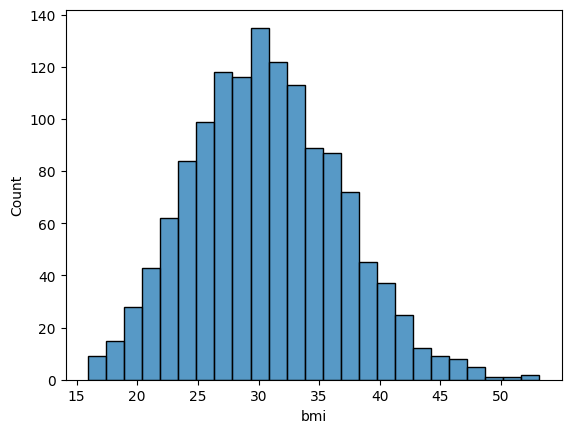

In [51]:
# 11-06-2026 --- want to plot a histgram so that bmi can represent 
# print(new_data)

sns.histplot(new_data['bmi'])


In [52]:
print(new_data)

      age  is_female     bmi  children  is_smoker      charges  \
0      19          1  27.900         0          1  16884.92400   
1      18          0  33.770         1          0   1725.55230   
2      28          0  33.000         3          0   4449.46200   
3      33          0  22.705         0          0  21984.47061   
4      32          0  28.880         0          0   3866.85520   
...   ...        ...     ...       ...        ...          ...   
1333   50          0  30.970         3          0  10600.54830   
1334   18          1  31.920         0          0   2205.98080   
1335   18          1  36.850         0          0   1629.83350   
1336   21          1  25.800         0          0   2007.94500   
1337   61          1  29.070         0          1  29141.36030   

      region_northeast  region_northwest  region_southeast  region_southwest  
0                False             False             False              True  
1                False             False         

In [53]:
# want to create some additional columns so that we can define the bmi into different categories 
# pd.cut() 
# bins - range 0-20, type float
new_data['bmi_category'] = pd.cut(
    new_data['bmi'], 
    bins=[0, 18.5, 24.9, 29.9, float('inf')],
    labels=['Underweight', 'Normal', 'Overweight', 'Obese']
)

In [54]:
# here, we want to create additional columns on the basis bmi_category 
# new_data = pd.get_dummies(new_data,columns = ['bmi_category'])

new_data = pd.get_dummies(new_data, columns=['bmi_category'])


In [55]:
# print(new_data)
# bmi_values currently present as False and True which is converted into the 0 * 1
new_data = new_data.astype(int)

In [56]:
print(new_data)

      age  is_female  bmi  children  is_smoker  charges  region_northeast  \
0      19          1   27         0          1    16884                 0   
1      18          0   33         1          0     1725                 0   
2      28          0   33         3          0     4449                 0   
3      33          0   22         0          0    21984                 0   
4      32          0   28         0          0     3866                 0   
...   ...        ...  ...       ...        ...      ...               ...   
1333   50          0   30         3          0    10600                 0   
1334   18          1   31         0          0     2205                 1   
1335   18          1   36         0          0     1629                 0   
1336   21          1   25         0          0     2007                 0   
1337   61          1   29         0          1    29141                 0   

      region_northwest  region_southeast  region_southwest  \
0            

In [ ]:
# want to check the total number of columns in the given dataset
print(new_data.columns)

Index(['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges',
       'region_northeast', 'region_northwest', 'region_southeast',
       'region_southwest', 'bmi_category_Underweight', 'bmi_category_Normal',
       'bmi_category_Overweight', 'bmi_category_Obese'],
      dtype='object')


In [59]:
print(new_data[['bmi_category_Normal','bmi_category_Underweight','bmi_category_Overweight','bmi_category_Obese']])

      bmi_category_Normal  bmi_category_Underweight  bmi_category_Overweight  \
0                       0                         0                        1   
1                       0                         0                        0   
2                       0                         0                        0   
3                       1                         0                        0   
4                       0                         0                        1   
...                   ...                       ...                      ...   
1333                    0                         0                        0   
1334                    0                         0                        0   
1335                    0                         0                        0   
1336                    0                         0                        1   
1337                    0                         0                        1   

      bmi_category_Obese  
0           

In [ ]:
# here we are preprocessing the data. 
# import sklearn then perform preprocessing 

# Here we are performing Standarization and Normalization

from sklearn.preprocessing import StandardScaler
cols = ['age','bmi','children']
scaler = StandardScaler()

new_data[cols] = scaler.fit_transform(new_data[cols])

In [61]:
print(new_data)

           age  is_female       bmi  children  is_smoker  charges  \
0    -1.440418          1 -0.517949 -0.909234          1    16884   
1    -1.511647          0  0.462463 -0.079442          0     1725   
2    -0.799350          0  0.462463  1.580143          0     4449   
3    -0.443201          0 -1.334960 -0.909234          0    21984   
4    -0.514431          0 -0.354547 -0.909234          0     3866   
...        ...        ...       ...       ...        ...      ...   
1333  0.767704          0 -0.027743  1.580143          0    10600   
1334 -1.511647          1  0.135659 -0.909234          0     2205   
1335 -1.511647          1  0.952670 -0.909234          0     1629   
1336 -1.297958          1 -0.844753 -0.909234          0     2007   
1337  1.551231          1 -0.191145 -0.909234          1    29141   

      region_northeast  region_northwest  region_southeast  region_southwest  \
0                    0                 0                 0                 1   
1          